# Preparar MapBiomas

## 1. Objetivos

Este notebook tem como objetivo preparar os dados de uso e cobertura da terra do MapBiomas, Coleção 11, referentes aos anos de 1985 e 2025, para o município de Teresópolis, localizado na região serrana do estado do Rio de Janeiro.

O processamento compreende a inspeção dos rasters originais, a obtenção e validação do limite municipal, a compatibilização dos sistemas de referência de coordenadas, o recorte espacial dos dois anos e a validação dos arquivos produzidos.

Busca-se garantir a integridade dos dados, preservar os códigos categóricos originais e verificar a compatibilidade espacial entre os rasters, condição necessária para a análise pixel a pixel das mudanças e transições ocorridas ao longo do período de 40 anos.

Ao final, serão disponibilizados dois rasters recortados para Teresópolis, acompanhados de verificações de integridade e compatibilidade espacial, para utilização no Notebook 03 — Mudanças e transições de uso e cobertura da terra.

## 2. Etapas

- Configuração do ambiente e dos caminhos do projeto.
- Carregamento e inspeção dos rasters originais de 1985 e 2025.
- Obtenção, seleção e validação do limite municipal de Teresópolis.
- Salvamento e validação do limite municipal em GeoPackage.
- Verificação da compatibilidade espacial dos rasters originais.
- Recorte dos rasters de 1985 e 2025 para o município.
- Salvamento e validação dos arquivos GeoTIFF recortados.
- Identificação dos códigos de classe presentes em cada ano.
- Verificação da compatibilidade espacial entre os rasters recortados.
- Visualização exploratória em tons de cinza e validação espacial.
- Conclusão do processamento e preparação dos dados para o Notebook 03.

## 3. Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path
from rasterio.plot import show

from rasterio.mask import mask
from geobr import read_municipality

print("Bibliotecas importadas com sucesso.")
print("Rasterio:", rasterio.__version__)
print("GeoPandas:", gpd.__version__)

Bibliotecas importadas com sucesso.
Rasterio: 1.5.0
GeoPandas: 1.1.4


## 4. Configuração do ambiente e dos caminhos

### Detecção automática da raiz do projeto

In [2]:
#detecção automática da raiz
def encontrar_raiz_projeto(nome_raiz="projeto_teresopolis"):
    """
    Localiza a raiz do projeto a partir do diretório atual
    ou de seus diretórios ancestrais.
    """
    diretorio_atual = Path.cwd().resolve()

    for diretorio in [diretorio_atual, *diretorio_atual.parents]:
        if diretorio.name == nome_raiz:
            return diretorio

    raise FileNotFoundError(
        f"Não foi possível localizar a pasta '{nome_raiz}'. "
        "Verifique se o notebook está dentro da estrutura do projeto."
    )


PROJECT_ROOT = encontrar_raiz_projeto()

print("Raiz do projeto:", PROJECT_ROOT)

Raiz do projeto: G:\Meu Drive\projeto_teresopolis


### Definição dos caminhos

In [3]:
# Diretórios principais
DADOS_DIR = PROJECT_ROOT / "dados"
BRUTOS_DIR = DADOS_DIR / "brutos"
INTERMEDIARIOS_DIR = DADOS_DIR / "intermediarios"

# Diretório dos dados de uso e cobertura da terra
USO_COBERTURA_DIR = BRUTOS_DIR / "uso_cobertura"

# Rasters originais do MapBiomas — Coleção 11
arquivo_mapbiomas_1985 = (
    USO_COBERTURA_DIR / "brazil_coverage-col11_1985.tif"
)

arquivo_mapbiomas_2025 = (
    USO_COBERTURA_DIR / "brazil_coverage-col11_2025.tif"
)

# Limite municipal
arquivo_limite = (
    INTERMEDIARIOS_DIR / "limite_teresopolis.gpkg"
)

# Rasters recortados para Teresópolis
arquivo_recortado_1985 = (
    INTERMEDIARIOS_DIR / "mapbiomas_teresopolis_1985.tif"
)

arquivo_recortado_2025 = (
    INTERMEDIARIOS_DIR / "mapbiomas_teresopolis_2025.tif"
)

print("Raiz do projeto:", PROJECT_ROOT)
print("Raster de 1985:", arquivo_mapbiomas_1985)
print("Raster de 2025:", arquivo_mapbiomas_2025)
print("Limite municipal:", arquivo_limite)
print("Saída de 1985:", arquivo_recortado_1985)
print("Saída de 2025:", arquivo_recortado_2025)

Raiz do projeto: G:\Meu Drive\projeto_teresopolis
Raster de 1985: G:\Meu Drive\projeto_teresopolis\dados\brutos\uso_cobertura\brazil_coverage-col11_1985.tif
Raster de 2025: G:\Meu Drive\projeto_teresopolis\dados\brutos\uso_cobertura\brazil_coverage-col11_2025.tif
Limite municipal: G:\Meu Drive\projeto_teresopolis\dados\intermediarios\limite_teresopolis.gpkg
Saída de 1985: G:\Meu Drive\projeto_teresopolis\dados\intermediarios\mapbiomas_teresopolis_1985.tif
Saída de 2025: G:\Meu Drive\projeto_teresopolis\dados\intermediarios\mapbiomas_teresopolis_2025.tif


### Validação dos caminhos dos arquivos de entrada

In [4]:
# Verificar a existência dos dois rasters originais
arquivos_entrada = {
    1985: arquivo_mapbiomas_1985,
    2025: arquivo_mapbiomas_2025,
}

for ano, caminho in arquivos_entrada.items():
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Raster do MapBiomas de {ano} não encontrado em:\n"
            f"{caminho}"
        )

    tamanho_gb = caminho.stat().st_size / (1024 ** 3)

    print(
        f"Raster de {ano} localizado: "
        f"{caminho.name} ({tamanho_gb:.2f} GB)"
    )

print("\nOs dois arquivos de entrada foram localizados.")

Raster de 1985 localizado: brazil_coverage-col11_1985.tif (0.63 GB)
Raster de 2025 localizado: brazil_coverage-col11_2025.tif (0.71 GB)

Os dois arquivos de entrada foram localizados.


## 5. Carregamento e inspeção dos rasters originais

### Inspecionar os metadados dos rasters originais

In [5]:
for ano, caminho in arquivos_entrada.items():
    print(f"\n{'=' * 15} MAPBIOMAS {ano} {'=' * 15}")

    with rasterio.open(caminho) as src:
        print("CRS:", src.crs)
        print("Dimensões (largura, altura):", src.width, src.height)
        print("Número de bandas:", src.count)
        print("Resolução:", src.res)
        print("NoData:", src.nodata)
        print("Tipo de dado:", src.dtypes)
        print("Extensão:", src.bounds)


=============== MAPBIOMAS 1985 ===============
CRS: EPSG:4326
Dimensões (largura, altura): 154470 146501
Número de bandas: 1
Resolução: (0.00026949458523585647, 0.00026949458523585647)
NoData: None
Tipo de dado: ('uint8',)
Extensão: BoundingBox(left=-74.02099974839176, bottom=-34.05818669293707, right=-32.39217116700901, top=5.42303953870114)

=============== MAPBIOMAS 2025 ===============
CRS: EPSG:4326
Dimensões (largura, altura): 154470 146501
Número de bandas: 1
Resolução: (0.00026949458523585647, 0.00026949458523585647)
NoData: None
Tipo de dado: ('uint8',)
Extensão: BoundingBox(left=-74.02099974839176, bottom=-34.05818669293707, right=-32.39217116700901, top=5.42303953870114)


## 6. Obtenção e preparação do limite municipal
Nesta etapa, será obtido o limite municipal de Teresópolis a partir da malha municipal disponibilizada pelo pacote geobr, utilizando o código oficial do IBGE. A geometria será inspecionada para verificar sua identificação, validade e sistema de referência de coordenadas antes de ser utilizada no recorte do raster MapBiomas.

### Carregamento da malha municipal do Rio de Janeiro

In [6]:
# Obter a malha municipal do estado do Rio de Janeiro
municipios_rj = read_municipality(
    code_muni="RJ",
    year=2022
)

# Inspecionar os campos disponíveis
print("Quantidade de municípios:", len(municipios_rj))
print("CRS da malha municipal:", municipios_rj.crs)
print("Colunas disponíveis:", municipios_rj.columns.tolist())

Quantidade de municípios: 92
CRS da malha municipal: EPSG:4674
Colunas disponíveis: ['code_muni', 'name_muni', 'code_state', 'abbrev_state', 'name_state', 'code_region', 'name_region', 'year', 'geometry']


### Selecionar e salvar limite Teresópolis

In [7]:
# Código IBGE de Teresópolis
codigo_ibge = 3305802

# Identificar a coluna do código IBGE
coluna_codigo = next(
    (
        coluna for coluna in ["code_muni", "code_muni7"]
        if coluna in municipios_rj.columns
    ),
    None
)

if coluna_codigo is None:
    raise KeyError(
        "Coluna do código municipal não identificada. "
        "Confira os nomes apresentados na célula anterior."
    )

# Selecionar Teresópolis
teresopolis = municipios_rj.loc[
    municipios_rj[coluna_codigo].astype(int) == codigo_ibge
].copy()

if len(teresopolis) != 1:
    raise ValueError(
        f"Esperado um município; encontrados: {len(teresopolis)} feições."
    )

print("Município selecionado:")
display(teresopolis.drop(columns="geometry"))

print("CRS original:", teresopolis.crs)

Município selecionado:


,code_muni,name_muni,code_state,abbrev_state,name_state,code_region,name_region,year
85,3305802.0,Teresópolis,33.0,RJ,Rio de Janeiro,3.0,Sudeste,2022.0


CRS original: EPSG:4674


### Validação da geometria municipal

In [8]:
assert teresopolis.crs is not None, (
    "O limite municipal não possui CRS definido."
)

assert teresopolis.geometry.notna().all(), (
    "Existem geometrias ausentes no limite municipal."
)

assert teresopolis.geometry.is_valid.all(), (
    "A geometria municipal apresenta problemas de validade."
)

print("Geometria municipal válida.")
print("CRS:", teresopolis.crs)
print("Extensão:", teresopolis.total_bounds)

Geometria municipal válida.
CRS: EPSG:4674
Extensão: [-43.04625526 -22.4711724  -42.71100889 -22.12482456]


### Salvamento e validação do limite municipal

In [9]:
# Garantir que o diretório de saída exista
INTERMEDIARIOS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

arquivo_limite = (
    INTERMEDIARIOS_DIR / "limite_teresopolis.gpkg"
)

# Salvar o limite municipal
teresopolis.to_file(
    arquivo_limite,
    driver="GPKG"
)

print("Limite municipal salvo:", arquivo_limite)

C:\Users\claud\anaconda3\envs\AmbGEO\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Limite municipal salvo: G:\Meu Drive\projeto_teresopolis\dados\intermediarios\limite_teresopolis.gpkg


#### Validação

In [10]:
limite_validado = gpd.read_file(arquivo_limite)

assert len(limite_validado) == 1, (
    "O arquivo deve conter apenas uma feição municipal."
)

assert limite_validado.crs is not None, (
    "O arquivo salvo não possui CRS definido."
)

assert limite_validado.geometry.notna().all(), (
    "O arquivo salvo possui geometrias ausentes."
)

assert limite_validado.geometry.is_valid.all(), (
    "O arquivo salvo possui geometria inválida."
)

assert int(limite_validado[coluna_codigo].iloc[0]) == codigo_ibge, (
    "O código municipal do arquivo salvo não corresponde a Teresópolis."
)

print("Validação do limite municipal concluída.")
print("Arquivo:", arquivo_limite.name)
print("CRS:", limite_validado.crs)
print("Número de feições:", len(limite_validado))

Validação do limite municipal concluída.
Arquivo: limite_teresopolis.gpkg
CRS: EPSG:4674
Número de feições: 1


## 7. Compatibilidade espacial entre os rasters e o limite municipal

Nesta etapa, verificaremos a compatibilidade espacial entre os rasters do MapBiomas de 1985 e 2025 e o limite municipal de Teresópolis. Serão conferidos o sistema de referência de coordenadas (CRS), a resolução espacial e a extensão geográfica dos arquivos, garantindo que o limite municipal possa ser utilizado corretamente no recorte dos dois rasters.

O objetivo é identificar eventuais incompatibilidades antes do processamento, preservando a consistência espacial necessária para a análise das mudanças de uso e cobertura da terra entre 1985 e 2025.

### Definição dos arquivos de entrada

In [11]:
# Verificação da existência dos arquivos
arquivos_entrada = {
    "MapBiomas 1985": arquivo_mapbiomas_1985,
    "MapBiomas 2025": arquivo_mapbiomas_2025,
    "Limite municipal": arquivo_limite
}

for nome, caminho in arquivos_entrada.items():
    if not caminho.exists():
        raise FileNotFoundError(
            f"Arquivo não encontrado ({nome}): {caminho}"
        )
    print(f"{nome}: encontrado")

MapBiomas 1985: encontrado
MapBiomas 2025: encontrado
Limite municipal: encontrado


### Verificação do alinhamento entre os rasters

In [12]:
with rasterio.open(arquivo_mapbiomas_1985) as src_1985, \
     rasterio.open(arquivo_mapbiomas_2025) as src_2025:

    verificacoes = {
        "CRS": src_1985.crs == src_2025.crs,
        "Resolução": src_1985.res == src_2025.res,
        "Dimensões": (
            src_1985.width == src_2025.width
            and src_1985.height == src_2025.height
        ),
        "Transformação espacial": (
            src_1985.transform == src_2025.transform
        ),
        "Extensão": src_1985.bounds == src_2025.bounds
    }

for item, resultado in verificacoes.items():
    print(f"{item}: {'OK' if resultado else 'INCOMPATÍVEL'}")

if not all(verificacoes.values()):
    raise ValueError(
        "Os rasters originais apresentam incompatibilidades espaciais."
    )

print("\nOs rasters originais possuem a mesma grade espacial.")

CRS: OK
Resolução: OK
Dimensões: OK
Transformação espacial: OK
Extensão: OK

Os rasters originais possuem a mesma grade espacial.


### Preparação do limite para o recorte

In [13]:
limite = gpd.read_file(arquivo_limite)

if limite.crs is None:
    raise ValueError("O limite municipal não possui CRS definido.")

with rasterio.open(arquivo_mapbiomas_1985) as src_1985, \
     rasterio.open(arquivo_mapbiomas_2025) as src_2025:

    crs_1985 = src_1985.crs
    crs_2025 = src_2025.crs

limite_1985 = limite.to_crs(crs_1985)
limite_2025 = limite.to_crs(crs_2025)

print("CRS do limite para 1985:", limite_1985.crs)
print("CRS do limite para 2025:", limite_2025.crs)

CRS do limite para 1985: GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]
CRS do limite para 2025: GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]


## 8. Recorte dos rasters do MapBiomas pelo limite municipal
Descrição da seção: Nesta etapa, recortaremos os rasters do MapBiomas de 1985 e 2025 utilizando o limite municipal de Teresópolis. O objetivo é reduzir os arquivos à área de estudo, mantendo os códigos originais das classes de uso e cobertura da terra e preservando as informações espaciais necessárias às análises posteriores.

Os arquivos recortados serão salvos na pasta dados/intermediarios/ e utilizados no Notebook 03, dedicado à análise das mudanças e transições entre 1985 e 2025.

### Definição dos arquivos de saída
**Ação**: adicionar uma célula de código para definir os caminhos dos rasters recortados.

In [14]:
arquivo_recortado_1985 = (
    INTERMEDIARIOS_DIR / "mapbiomas_teresopolis_1985.tif"
)

arquivo_recortado_2025 = (
    INTERMEDIARIOS_DIR / "mapbiomas_teresopolis_2025.tif"
)

INTERMEDIARIOS_DIR.mkdir(parents=True, exist_ok=True)

### Recorte dos rasters
**Ação**: adicionar uma célula para executar o recorte dos dois anos com o mesmo procedimento.

In [15]:
NODATA_VALOR = 255

rasters_entrada = {
    1985: (arquivo_mapbiomas_1985, arquivo_recortado_1985),
    2025: (arquivo_mapbiomas_2025, arquivo_recortado_2025)
}

for ano, (arquivo_entrada, arquivo_saida) in rasters_entrada.items():

    with rasterio.open(arquivo_entrada) as src:

        # Reprojetar o limite para o CRS do raster
        limite_recorte = limite.to_crs(src.crs)

        # Recortar o raster pela geometria municipal
        imagem_recortada, transformacao = mask(
            src,
            limite_recorte.geometry,
            crop=True,
            filled=True,
            nodata=NODATA_VALOR
        )

        # Atualizar os metadados do raster de saída
        metadados = src.meta.copy()
        metadados.update({
            "driver": "GTiff",
            "height": imagem_recortada.shape[1],
            "width": imagem_recortada.shape[2],
            "transform": transformacao,
            "nodata": NODATA_VALOR,
            "compress": "LZW"
        })

    # Salvar o raster recortado
    with rasterio.open(arquivo_saida, "w", **metadados) as dst:
        dst.write(imagem_recortada)

    print(f"MapBiomas {ano} recortado e salvo.")
    print(f"Arquivo: {arquivo_saida.name}")

MapBiomas 1985 recortado e salvo.
Arquivo: mapbiomas_teresopolis_1985.tif
MapBiomas 2025 recortado e salvo.
Arquivo: mapbiomas_teresopolis_2025.tif


### Verificação inicial dos arquivos gerados
**Ação**: adicionar uma célula para confirmar que os dois arquivos foram criados e verificar suas dimensões e seus sistemas de referência.

In [16]:
for ano, arquivo in [
    (1985, arquivo_recortado_1985),
    (2025, arquivo_recortado_2025)
]:
    if not arquivo.exists():
        raise FileNotFoundError(
            f"O raster recortado de {ano} não foi encontrado."
        )

    with rasterio.open(arquivo) as src:
        print(f"\nMapBiomas {ano}")
        print("Arquivo:", arquivo.name)
        print("CRS:", src.crs)
        print("Dimensões:", src.width, "x", src.height)
        print("Resolução:", src.res)
        print("NoData:", src.nodata)
        print("Extensão:", src.bounds)


MapBiomas 1985
Arquivo: mapbiomas_teresopolis_1985.tif
CRS: EPSG:4326
Dimensões: 1245 x 1286
Resolução: (0.00026949458523585647, 0.00026949458523585647)
NoData: 255.0
Extensão: BoundingBox(left=-43.04637009972336, bottom=-22.47126700072142, right=-42.71084934110472, top=-22.124696964108107)

MapBiomas 2025
Arquivo: mapbiomas_teresopolis_2025.tif
CRS: EPSG:4326
Dimensões: 1245 x 1286
Resolução: (0.00026949458523585647, 0.00026949458523585647)
NoData: 255.0
Extensão: BoundingBox(left=-43.04637009972336, bottom=-22.47126700072142, right=-42.71084934110472, top=-22.124696964108107)


## 9. Validação dos rasters recortados
Descrição da seção: Nesta etapa, verificaremos a integridade dos rasters recortados de 1985 e 2025, confirmando se os arquivos foram gerados corretamente, se contêm pixels válidos e se os códigos das classes foram preservados. Também verificaremos a consistência dos metadados e a presença de valores inesperados.

Essa validação é importante para garantir a confiabilidade dos dados que serão utilizados no Notebook 03 para calcular áreas, identificar ganhos e perdas e analisar as transições de uso e cobertura da terra.

### Verificação da integridade dos arquivos

In [17]:
import numpy as np
import rasterio

rasters_recortados = {
    1985: arquivo_recortado_1985,
    2025: arquivo_recortado_2025
}

for ano, caminho in rasters_recortados.items():

    with rasterio.open(caminho) as src:
        dados = src.read(1)
        nodata = src.nodata

        mascara_validos = (
            dados != nodata
            if nodata is not None
            else np.ones(dados.shape, dtype=bool)
        )

        pixels_validos = int(mascara_validos.sum())
        pixels_nodata = int(dados.size - pixels_validos)

        print(f"\n{'=' * 12} MAPBIOMAS {ano} {'=' * 12}")
        
        print("Total de pixels:", dados.size)
        print("Pixels válidos:", pixels_validos)
        print("Pixels NoData:", pixels_nodata)

        if pixels_validos == 0:
            raise ValueError(
                f"O raster de {ano} não possui pixels válidos."
            )


============ MAPBIOMAS 1985 ============
Total de pixels: 1601070
Pixels válidos: 933319
Pixels NoData: 667751

============ MAPBIOMAS 2025 ============
Total de pixels: 1601070
Pixels válidos: 933319
Pixels NoData: 667751


C:\Users\claud\AppData\Local\Temp\ipykernel_44144\496925853.py:12: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dados = src.read(1)


### Identificação dos códigos de classe presentes

In [18]:
for ano, caminho in rasters_recortados.items():

    with rasterio.open(caminho) as src:
        dados = src.read(1)
        nodata = src.nodata

    if nodata is not None:
        valores_validos = dados[dados != nodata]
    else:
        valores_validos = dados.ravel()

    codigos, contagens = np.unique(
        valores_validos,
        return_counts=True
    )

    print(f"\nCódigos presentes em {ano}:")
    for codigo, quantidade in zip(codigos, contagens):
        print(f"Código {int(codigo)}: {quantidade:,} pixels")


Códigos presentes em 1985:
Código 3: 467,375 pixels
Código 9: 16 pixels
Código 11: 94 pixels
Código 12: 21,063 pixels
Código 15: 244,091 pixels
Código 21: 178,272 pixels
Código 24: 11,971 pixels
Código 25: 350 pixels
Código 29: 8,958 pixels
Código 30: 33 pixels
Código 33: 1,032 pixels
Código 41: 64 pixels


C:\Users\claud\AppData\Local\Temp\ipykernel_44144\1561996909.py:4: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dados = src.read(1)



Códigos presentes em 2025:
Código 3: 554,151 pixels
Código 9: 3,992 pixels
Código 11: 130 pixels
Código 12: 28,428 pixels
Código 15: 184,730 pixels
Código 21: 120,908 pixels
Código 24: 29,774 pixels
Código 25: 1,213 pixels
Código 29: 8,887 pixels
Código 30: 106 pixels
Código 32: 73 pixels
Código 33: 927 pixels


### Comparação das classes entre os anos

In [19]:
codigos_por_ano = {}

for ano, caminho in rasters_recortados.items():

    with rasterio.open(caminho) as src:
        dados = src.read(1)
        nodata = src.nodata

    if nodata is not None:
        valores_validos = dados[dados != nodata]
    else:
        valores_validos = dados.ravel()

    codigos_por_ano[ano] = set(
        np.unique(valores_validos).astype(int)
    )

comuns = codigos_por_ano[1985] & codigos_por_ano[2025]
somente_1985 = codigos_por_ano[1985] - codigos_por_ano[2025]
somente_2025 = codigos_por_ano[2025] - codigos_por_ano[1985]

print("Códigos presentes nos dois anos:", sorted(comuns))
print("Códigos presentes somente em 1985:", sorted(somente_1985))
print("Códigos presentes somente em 2025:", sorted(somente_2025))

C:\Users\claud\AppData\Local\Temp\ipykernel_44144\3468563867.py:6: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dados = src.read(1)


Códigos presentes nos dois anos: [np.int64(3), np.int64(9), np.int64(11), np.int64(12), np.int64(15), np.int64(21), np.int64(24), np.int64(25), np.int64(29), np.int64(30), np.int64(33)]
Códigos presentes somente em 1985: [np.int64(41)]
Códigos presentes somente em 2025: [np.int64(32)]


### Verificação final dos valores NoData

In [20]:
for ano, caminho in rasters_recortados.items():

    with rasterio.open(caminho) as src:
        dados = src.read(1)
        nodata = src.nodata

    if nodata is not None:
        ocorrencias_nodata = int(np.count_nonzero(dados == nodata))
        print(
            f"{ano}: {ocorrencias_nodata:,} pixels identificados como NoData."
        )

1985: 667,751 pixels identificados como NoData.
2025: 667,751 pixels identificados como NoData.


C:\Users\claud\AppData\Local\Temp\ipykernel_44144\147431968.py:4: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dados = src.read(1)


**Interpretação dos pixels NoData**

Os rasters recortados de 1985 e 2025 apresentam 667.751 pixels NoData cada. Essa quantidade não indica, por si só, falhas ou ausência de dados no município. Como o recorte é armazenado em uma matriz retangular que envolve o limite municipal, os pixels situados fora do polígono de Teresópolis são preenchidos com o valor NoData.

A interpretação desses valores deve considerar a localização espacial dos pixels. Os valores NoData externos ao limite municipal são esperados, enquanto eventuais ocorrências dentro da área municipal devem ser investigadas para verificar se correspondem a dados ausentes ou a outras particularidades do raster.

Assim, a quantidade total de pixels NoData deve ser interpretada em conjunto com o limite municipal, não sendo suficiente, isoladamente, para concluir que existem problemas nos dados.

## 10 — Visualização exploratória e validação espacial dos rasters recortados
Nesta etapa, visualizaremos os rasters do MapBiomas de 1985 e 2025, recortados para o município de Teresópolis. A representação permitirá inspecionar a distribuição espacial dos valores e verificar visualmente a integridade dos recortes. Também verificaremos se as extensões dos arquivos são compatíveis com a área de estudo e se existem pixels sem dados dentro dos recortes.

### Visualização dos mapas de 1985 e 2025

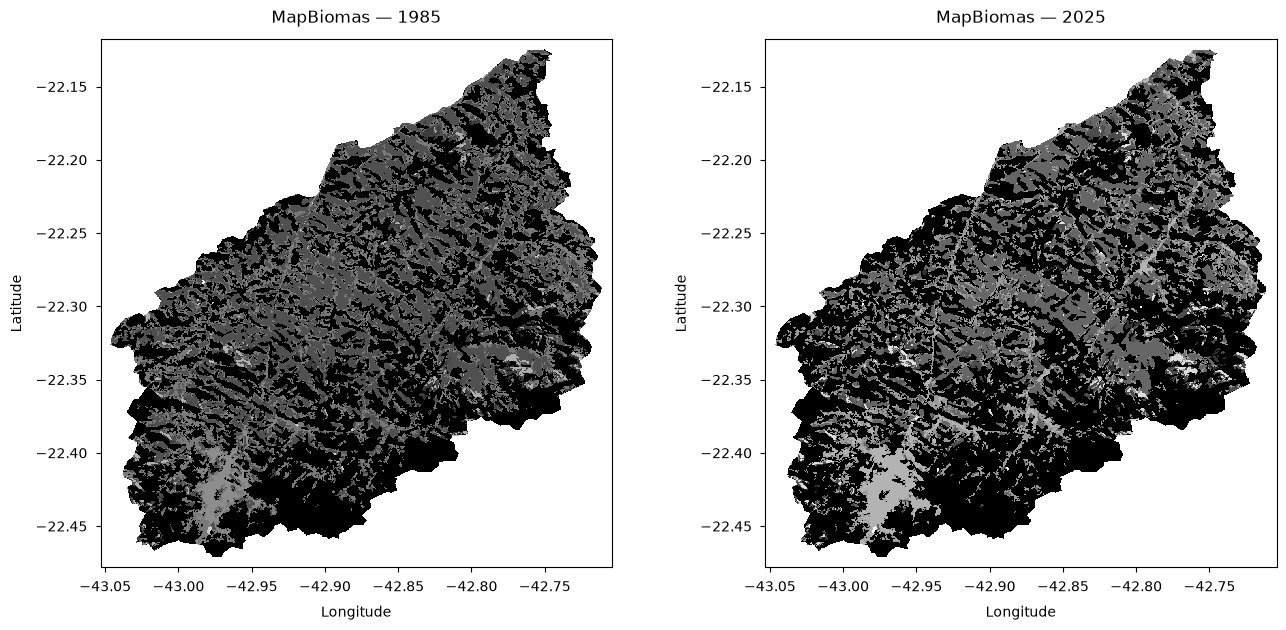

In [21]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 7))

for eixo, ano, caminho in [
    (eixos[0], 1985, arquivo_recortado_1985),
    (eixos[1], 2025, arquivo_recortado_2025),
]:
    with rasterio.open(caminho) as src:
        dados = src.read(1, masked=True)
        esquerda = src.bounds.left
        direita = src.bounds.right
        inferior = src.bounds.bottom
        superior = src.bounds.top

    # Margem ao redor do raster
    margem_x = (direita - esquerda) * 0.02
    margem_y = (superior - inferior) * 0.02

    eixo.imshow(
        dados,
        extent=[esquerda, direita, inferior, superior],
        origin="upper",
        interpolation="nearest",
        cmap="gray"
    )

    # Afastar a moldura do mapa
    eixo.set_xlim(esquerda - margem_x, direita + margem_x)
    eixo.set_ylim(inferior - margem_y, superior + margem_y)

    eixo.set_title(f"MapBiomas — {ano}", pad=12)
    eixo.set_xlabel("Longitude", labelpad=8)
    eixo.set_ylabel("Latitude", labelpad=8)
    eixo.tick_params(axis="both", pad=6)

fig.subplots_adjust(
    left=0.08,
    right=0.92,
    bottom=0.12,
    top=0.88,
    wspace=0.30
)

plt.show()

### Verificação da extensão em relação ao limite municipal

In [22]:
limite = gpd.read_file(arquivo_limite)

for ano, caminho in rasters_recortados.items():

    with rasterio.open(caminho) as src:
        limite_raster = limite.to_crs(src.crs)

        raster_bounds = src.bounds
        limite_bounds = limite_raster.total_bounds

        sobreposicao = (
            raster_bounds.left <= limite_bounds[2]
            and raster_bounds.right >= limite_bounds[0]
            and raster_bounds.bottom <= limite_bounds[3]
            and raster_bounds.top >= limite_bounds[1]
        )

        print(f"\nMapBiomas {ano}")
        print("Extensão do raster:", raster_bounds)
        print("Extensão do limite:", limite_bounds)
        print("Extensões se sobrepõem:", sobreposicao)

        if not sobreposicao:
            raise ValueError(
                f"O raster de {ano} não se sobrepõe ao limite municipal."
            )


MapBiomas 1985
Extensão do raster: BoundingBox(left=-43.04637009972336, bottom=-22.47126700072142, right=-42.71084934110472, top=-22.124696964108107)
Extensão do limite: [-43.04625526 -22.4711724  -42.71100889 -22.12482456]
Extensões se sobrepõem: True

MapBiomas 2025
Extensão do raster: BoundingBox(left=-43.04637009972336, bottom=-22.47126700072142, right=-42.71084934110472, top=-22.124696964108107)
Extensão do limite: [-43.04625526 -22.4711724  -42.71100889 -22.12482456]
Extensões se sobrepõem: True


### Verificação da compatibilidade espacial entre os rasters recortados

In [23]:
with rasterio.open(arquivo_recortado_1985) as r85, \
     rasterio.open(arquivo_recortado_2025) as r25:

    alinhados = (
        r85.crs == r25.crs
        and r85.res == r25.res
        and r85.shape == r25.shape
        and r85.transform == r25.transform
    )

    print("Grades espaciais compatíveis:", alinhados)

    if not alinhados:
        raise ValueError(
            "Os rasters recortados não estão alinhados espacialmente."
        )

Grades espaciais compatíveis: True


## 11. Conclusão

Neste notebook, foram preparados os rasters de uso e cobertura da terra do MapBiomas, Coleção 11, referentes aos anos de 1985 e 2025, para o município de Teresópolis, localizado na região serrana do estado do Rio de Janeiro.

Inicialmente, os rasters originais foram carregados e inspecionados, e o limite municipal foi obtido a partir da malha municipal disponibilizada pelo pacote geobr. A geometria de Teresópolis foi validada e salva em GeoPackage, constituindo a referência espacial utilizada no processamento.

Em seguida, foi verificada a compatibilidade espacial dos rasters originais, e o limite municipal foi preparado para o recorte de cada ano. Os rasters foram recortados pela geometria municipal, preservando os códigos originais das classes e utilizando o valor 255 para identificar os pixels externos à área de interesse.

Os arquivos resultantes foram submetidos a verificações de integridade, incluindo a conferência das dimensões, dos sistemas de referência de coordenadas, das extensões espaciais, dos valores NoData, da quantidade de pixels válidos e dos códigos de classe presentes em cada ano. A inspeção visual em tons de cinza complementou essas verificações, sem antecipar a definição das cores temáticas das classes.

O processamento resultou em dois rasters recortados para Teresópolis, correspondentes a 1985 e 2025. Esses produtos constituem a base de dados para o Notebook 03, dedicado à análise das mudanças e transições de uso e cobertura da terra no período de 40 anos.

Antes da comparação pixel a pixel, a compatibilidade das grades espaciais dos rasters recortados deve ser confirmada. Com essa validação, os dados estarão preparados para a quantificação das áreas por classe, a análise das transições e a produção de mapas temáticos comparáveis.

Dessa forma, este notebook estabelece uma etapa reprodutível de preparação e validação dos dados geoespaciais necessários à investigação da dinâmica temporal do uso e da cobertura da terra em Teresópolis.